*Lab 6*

*Name: Abdulaziz Khaled Alhassan*

*ID: 2240006848*

*Group: 7MA1*

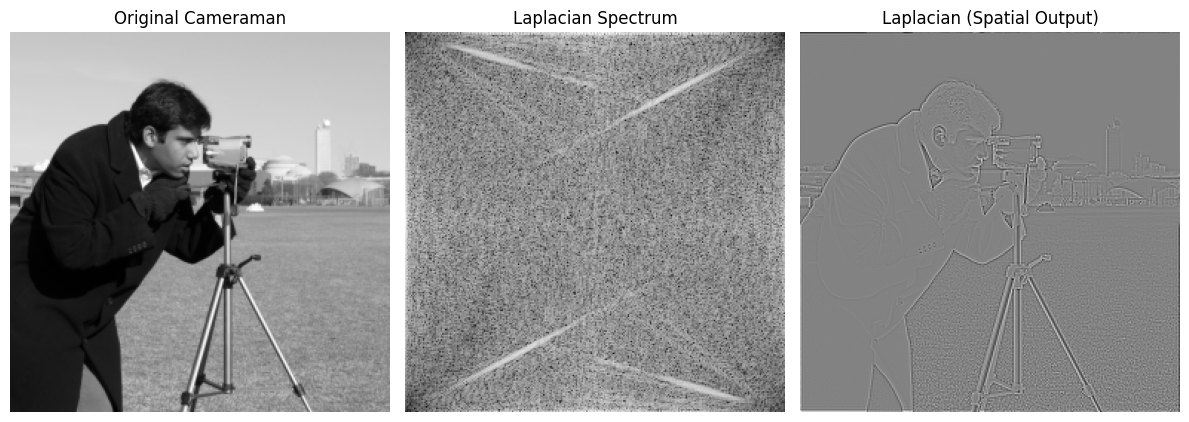

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

image = data.camera()
image = resize(image, (256, 256)) # Resize for faster FFT (optional)
# Get image size
M, N = image.shape
# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)
# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter
# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real
# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')
plt.tight_layout()
plt.show()

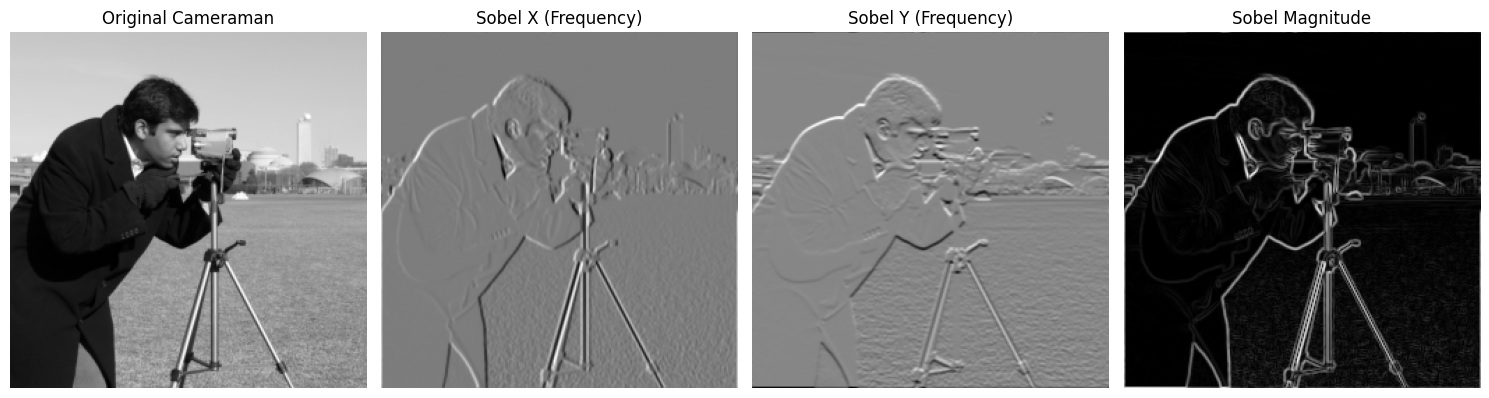

In [8]:
#Task 1
from numpy.fft import fft2, ifft2, ifftshift

image = resize(image, (256, 256))
M, N = image.shape

# 2. Sobel filters 
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# 3. Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center[cite: 1]
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left[cite: 1]

# 4. Compute FFT of image 
F_image = fft2(image)

# 5. FFT of centered Sobel filters 
H_sobel_x = center_embed_kernel(sobel_x, (M, N))
H_sobel_y = center_embed_kernel(sobel_y, (M, N))

# 6. Multiply in the frequency domain 
F_sobel_x = F_image * H_sobel_x
F_sobel_y = F_image * H_sobel_y

# Inverse FFT to get spatial results 
sobel_x_image = ifft2(F_sobel_x).real
sobel_y_image = ifft2(F_sobel_y).real
sobel_magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

# 7. Plot 
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_x_image, cmap='gray')
plt.title('Sobel X (Frequency)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_y_image, cmap='gray')
plt.title('Sobel Y (Frequency)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Magnitude')
plt.axis('off')

plt.tight_layout()
plt.show()